In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ---- 0. Setup ---------------------------------------------------------
# !pip install torch torchaudio librosa scikit-learn matplotlib pandas -q

import os
import random
import pathlib
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import librosa
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cuda


In [ ]:
# ---- Config -------------------------------------------------------------
DATA_DIR = "/content/drive/MyDrive/Research 2026/Segmented"            # folder containing your STEMI/ and Normal/ subfolders — set this
CLASS_FOLDERS = {"normal_segment": 0, "myocardial_segment": 1}   # folder name -> label (1 = positive / MI class)
CLASSES = ["Normal", "Myocardial"]   # index 0 = Normal, index 1 = MI (used for display/reports)

SAMPLE_RATE = 4000           # Hz — target rate everything is resampled to. Your segmented
                              # files are actually 22050 Hz, but heart-sound content of
                              # interest is well under 800 Hz, so downsampling to 4000 Hz
                              # (matching the reference repo's assumption) loses nothing
                              # relevant and makes the STFT much cheaper.
FREQUENCY_HIGH = 800          # Hz, discard spectrogram content above this (reference repo default)
WINDOW_LENGTH_S = 0.050        # seconds, STFT window (reference repo default)
WINDOW_STEP_S = 0.020          # seconds, STFT hop

CLIP_SECONDS = 5             # pad/trim every recording to this length — matches your 5s segments
BATCH_SIZE = 16
EPOCHS = 60
LR = 1e-3
VAL_FRACTION = 0.2
TEST_FRACTION = 0.2

MIN_PATIENTS_PER_CLASS_FOR_SPLIT = 3  # below this, we can't do a meaningful held-out split
                                       # (see Section 3) — the notebook falls back to a
                                       # smoke test instead of crashing or lying with metrics

In [ ]:
import re
import pathlib
import pandas as pd

def parse_patient_and_site(filename, fallback_prefix):
    # Best-effort extraction of (patient_id, site, segment) from a filename.

    # 1. New Pattern: e.g. "Copy of Copy of Abdul Qadir_RUSB_10 Juni 2022_1.wav"
    # Matches "Copy of" (repeated), then Name, then Site (RUSB/LLSB/etc), then Date/Segment
    m = re.match(r"(?:Copy of\s+)+(.+?)_([A-Za-z]+)_.*?_(\d+)(?:_\d+)?\.wav$", filename, flags=re.IGNORECASE)
    if m:
        name, site, segment = m.groups()
        # Clean name to use as patient ID
        patient_id = name.strip().replace(' ', '_')
        return f"{fallback_prefix}_{patient_id}", site.lower(), int(segment)

    # 2. Specific fix for files like "Copy of Apex_1.wav" -> Patient 70
    m = re.match(r"Copy of ([A-Za-z]+)_(\d+)\.wav$", filename, flags=re.IGNORECASE)
    if m:
        site, segment = m.groups()
        return f"{fallback_prefix}_70", site.lower(), int(segment)

    # 3. e.g. patient_1_Aan_apex_1.wav -> patient 1, site apex, segment 1
    m = re.match(r"patient (\d+)_.*?_([A-Za-z]+)_(\d+)\.wav$", filename, flags=re.IGNORECASE)
    if m:
        num, site, segment = m.groups()
        return f"{fallback_prefix}_{num}", site.lower(), int(segment)

    # 4. e.g. patient_1_Aan_apex.wav -> patient 1, site apex, no segment
    m = re.match(r"patient (\d+)_.*?_([A-Za-z]+)\.wav$", filename, flags=re.IGNORECASE)
    if m:
        num, site = m.groups()
        return f"{fallback_prefix}_{num}", site.lower(), None

    # 5. e.g. Copy of Apex__1__1.wav -> patient 1, site apex, segment 1
    m = re.match(r"Copy of ([A-Za-z]+) +(\d+)_+(\d+)\.wav$", filename, flags=re.IGNORECASE)
    if m:
        site, num, segment = m.groups()
        return f"{fallback_prefix}_{num}", site.lower(), int(segment)

    # 6. e.g. Copy of Apex__1_.wav -> patient 1, site apex, no segment
    m = re.match(r"Copy of ([A-Za-z]+) +(\d+)_?\.wav$", filename, flags=re.IGNORECASE)
    if m:
        site, num = m.groups()
        return f"{fallback_prefix}_{num}", site.lower(), None

    # 7. e.g. Copy of APEX_(1)_1.wav or Copy of APEX_(1).wav -> patient 1, site apex, segment (opt.)
    m = re.match(r"Copy of ([A-Za-z]+) \((\d+)\)(?:_(\d+))?\.wav$", filename, flags=re.IGNORECASE)
    if m:
        site, num, segment = m.groups()
        return f"{fallback_prefix}_{num}", site.lower(), (int(segment) if segment else None)

    # Unrecognised pattern: treat the whole filename as a unique patient, site/segment unknown
    return f"{fallback_prefix}_{pathlib.Path(filename).stem}", "unknown", None

def load_filepaths_from_folders(data_dir, class_folders):
    rows, unmatched = [], []
    for folder_name, label in class_folders.items():
        folder = pathlib.Path(data_dir) / folder_name
        if not folder.exists():
            print(f"Warning: folder not found: {folder}")
            continue
        class_name = CLASSES[label]
        for f in sorted(folder.glob("*.wav")):
            patient_id, site, segment = parse_patient_and_site(f.name, fallback_prefix=class_name)
            if site == "unknown":
                unmatched.append(f.name)
            rows.append({
                "filepath": str(f), "label": label, "class_name": class_name,
                "patient_id": patient_id, "site": site, "segment": segment,
            })

    if unmatched:
        print(f"Note: {len(unmatched)} file(s) didn't match the expected naming pattern "
              "and were each treated as their own patient:")
        for u in unmatched[:20]:
            print("  -", u)
        if len(unmatched) > 20:
            print(f"  ... and {len(unmatched) - 20} more")

    return pd.DataFrame(rows)

metadata = load_filepaths_from_folders(DATA_DIR, CLASS_FOLDERS)
print(metadata["class_name"].value_counts(), "\n(recordings)")
print(metadata.groupby("class_name")["patient_id"].nunique(), "\n(unique patients)")
metadata.head()

class_name
Normal        1680
Myocardial    1680
Name: count, dtype: int64 
(recordings)
class_name
Myocardial    71
Normal        70
Name: patient_id, dtype: int64 
(unique patients)


,filepath,label,class_name,patient_id,site,segment
0,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,1
1,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,2
2,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,3
3,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,4
4,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,5


In [ ]:
# Filter for Myocardial class only
mi_recordings = metadata[metadata['class_name'] == 'Myocardial']

# Count recordings per patient
mi_patient_counts = mi_recordings.groupby('patient_id').size().reset_index(name='recording_count')

# Sort by patient_id for readability
mi_patient_counts = mi_patient_counts.sort_values('patient_id')

print(f"Total unique Myocardial patients: {len(mi_patient_counts)}\n")
with pd.option_context('display.max_rows', None):
    display(mi_patient_counts)

Total unique Myocardial patients: 71



,patient_id,recording_count
0,Myocardial_70,18
1,Myocardial_Abdul_Qadir,12
2,Myocardial_Abdul_Rohman,18
3,Myocardial_Aceng_Zakaria,24
4,Myocardial_Ade_Rosadi,24
5,Myocardial_Agus_Sumpena,24
6,Myocardial_Agus_Supriadi,24
7,Myocardial_Agus_Wikayat,24
8,Myocardial_Amat,24
9,Myocardial_Aming,24


In [ ]:
target_patients = ["Myocardial_70", "Myocardial_Abdul_Qadir", "Myocardial_Abdul_Rohman"]

for pid in target_patients:
    print(f"--- Files for {pid} ---")
    files = metadata[metadata['patient_id'] == pid]['filepath'].apply(lambda x: pathlib.Path(x).name).tolist()
    for f in sorted(files):
        print(f"  - {f}")
    print(f"Total: {len(files)} files\n")

--- Files for Myocardial_70 ---
  - Copy of APEX_1.wav
  - Copy of APEX_2.wav
  - Copy of APEX_3.wav
  - Copy of APEX_4.wav
  - Copy of APEX_5.wav
  - Copy of APEX_6.wav
  - Copy of LLSB_1.wav
  - Copy of LLSB_2.wav
  - Copy of LLSB_3.wav
  - Copy of LLSB_4.wav
  - Copy of LLSB_5.wav
  - Copy of LLSB_6.wav
  - Copy of LUSB_1.wav
  - Copy of LUSB_2.wav
  - Copy of LUSB_3.wav
  - Copy of LUSB_4.wav
  - Copy of LUSB_5.wav
  - Copy of LUSB_6.wav
Total: 18 files

--- Files for Myocardial_Abdul_Qadir ---
  - Copy of Copy of Abdul Qadir_RUSB_10 Juni 2022_1.wav
  - Copy of Copy of Abdul Qadir_RUSB_10 Juni 2022_1_1.wav
  - Copy of Copy of Abdul Qadir_RUSB_10 Juni 2022_1_2.wav
  - Copy of Copy of Abdul Qadir_RUSB_10 Juni 2022_1_3.wav
  - Copy of Copy of Abdul Qadir_RUSB_10 Juni 2022_1_4.wav
  - Copy of Copy of Abdul Qadir_RUSB_10 Juni 2022_1_5.wav
  - Copy of Copy of Abdul Qadir_RUSB_10 Juni 2022_1_6.wav
  - Copy of Copy of Abdul Qadir_RUSB_10 Juni 2022_2.wav
  - Copy of Copy of Abdul Qadir_RUSB

In [ ]:
import os

# 1. Reassign APEX from Myocardial_70 to Myocardial_Abdul_Rohman
mask_rohman = (metadata['patient_id'] == 'Myocardial_70') & (metadata['site'] == 'apex')
metadata.loc[mask_rohman, 'patient_id'] = 'Myocardial_Abdul_Rohman'

# 2. Reassign LLSB and LUSB from Myocardial_70 to Myocardial_Abdul_Qadir
mask_qadir = (metadata['patient_id'] == 'Myocardial_70') & (metadata['site'].isin(['llsb', 'lusb']))
metadata.loc[mask_qadir, 'patient_id'] = 'Myocardial_Abdul_Qadir'

# Verify the new distribution
print("Updated Recording Counts per Patient:")
target_pids = ['Myocardial_70', 'Myocardial_Abdul_Qadir', 'Myocardial_Abdul_Rohman']
display(metadata[metadata['patient_id'].isin(target_pids)]['patient_id'].value_counts())

# Re-summarize unique patients
mi_count = metadata[metadata['class_name'] == 'Myocardial']['patient_id'].nunique()
print(f"\nTotal unique Myocardial patients: {mi_count}")

Updated Recording Counts per Patient:


,count
patient_id,
Myocardial_Abdul_Rohman,24
Myocardial_Abdul_Qadir,24



Total unique Myocardial patients: 70


In [ ]:
# Filter for Myocardial class only
mi_recordings = metadata[metadata['class_name'] == 'Myocardial']

# Count recordings per patient
mi_patient_counts = mi_recordings.groupby('patient_id').size().reset_index(name='recording_count')

# Sort by patient_id for readability
mi_patient_counts = mi_patient_counts.sort_values('patient_id')

print(f"Total unique Myocardial patients: {len(mi_patient_counts)}\n")
with pd.option_context('display.max_rows', None):
    display(mi_patient_counts)

Total unique Myocardial patients: 70



,patient_id,recording_count
0,Myocardial_Abdul_Qadir,24
1,Myocardial_Abdul_Rohman,24
2,Myocardial_Aceng_Zakaria,24
3,Myocardial_Ade_Rosadi,24
4,Myocardial_Agus_Sumpena,24
5,Myocardial_Agus_Supriadi,24
6,Myocardial_Agus_Wikayat,24
7,Myocardial_Amat,24
8,Myocardial_Aming,24
9,Myocardial_Ana_Suryana,24


In [ ]:
print(metadata["class_name"].value_counts(), "\n(recordings)")
print(metadata.groupby("class_name")["patient_id"].nunique(), "\n(unique patients)")
metadata.head()

class_name
Normal        1680
Myocardial    1680
Name: count, dtype: int64 
(recordings)
class_name
Myocardial    70
Normal        70
Name: patient_id, dtype: int64 
(unique patients)


,filepath,label,class_name,patient_id,site,segment
0,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,1
1,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,2
2,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,3
3,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,4
4,/content/drive/MyDrive/Research 2026/Segmented...,0,Normal,Normal_1,apex,5


Feature shape [freq_bins, time_frames]: (40, 248)


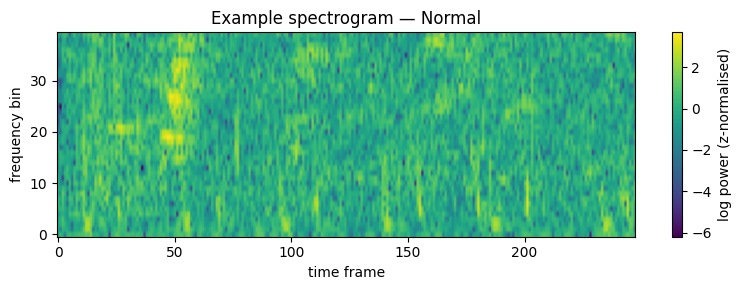

In [ ]:
def load_and_resample(filepath, sr=SAMPLE_RATE):
    signal, orig_sr = librosa.load(filepath, sr=sr, mono=True)
    return signal

def pad_or_trim(signal, sr=SAMPLE_RATE, seconds=CLIP_SECONDS):
    target_len = int(sr * seconds)
    if len(signal) >= target_len:
        return signal[:target_len]
    return np.pad(signal, (0, target_len - len(signal)))

def calculate_features(signal, sr=SAMPLE_RATE):
    # Band-limited log-STFT spectrogram, per-recording z-normalised.
    # Mirrors src/neural_networks.py:calculate_features from the reference repo.
    signal = signal.astype(np.float32)
    signal = signal - signal.mean()
    peak = np.abs(signal).max()
    if peak > 0:
        signal = signal / peak

    win_length = int(WINDOW_LENGTH_S * sr)
    hop_length = int(WINDOW_STEP_S * sr)

    stft = librosa.stft(signal, n_fft=win_length, hop_length=hop_length,
                         win_length=win_length, window="hann", center=False)
    power_spec = np.abs(stft) ** 2

    n_freq_bins = int(np.ceil(FREQUENCY_HIGH * WINDOW_LENGTH_S))
    power_spec = power_spec[:n_freq_bins]

    log_spec = np.log(power_spec + 1e-10)
    log_spec = (log_spec - log_spec.mean(axis=-1, keepdims=True)) / (
        log_spec.std(axis=-1, keepdims=True) + 1e-8
    )
    return log_spec.astype(np.float32)  # shape: [freq_bins, time_frames]

# Quick sanity check on one file
if len(metadata) > 0:
    sample_signal = pad_or_trim(load_and_resample(metadata.iloc[0]["filepath"]))
    sample_feat = calculate_features(sample_signal)
    print("Feature shape [freq_bins, time_frames]:", sample_feat.shape)

    plt.figure(figsize=(8, 3))
    plt.imshow(sample_feat, aspect="auto", origin="lower", cmap="viridis")
    plt.title(f"Example spectrogram — {metadata.iloc[0]['class_name']}")
    plt.xlabel("time frame"); plt.ylabel("frequency bin")
    plt.colorbar(label="log power (z-normalised)")
    plt.tight_layout(); plt.show()

In [ ]:
patient_df = (
    metadata.groupby("patient_id")
    .agg(label=("label", "first"), class_name=("class_name", "first"),
         n_recordings=("filepath", "count"))
    .reset_index()
)
print(patient_df)

class_patient_counts = patient_df["label"].value_counts()
enough_data = len(class_patient_counts) == 2 and class_patient_counts.min() >= MIN_PATIENTS_PER_CLASS_FOR_SPLIT

if enough_data:
    train_p, temp_p = train_test_split(
        patient_df, test_size=(VAL_FRACTION + TEST_FRACTION),
        stratify=patient_df["label"], random_state=SEED,
    )
    val_p, test_p = train_test_split(
        temp_p, test_size=TEST_FRACTION / (VAL_FRACTION + TEST_FRACTION),
        stratify=temp_p["label"], random_state=SEED,
    )
    train_df = metadata[metadata["patient_id"].isin(train_p["patient_id"])]
    val_df = metadata[metadata["patient_id"].isin(val_p["patient_id"])]
    test_df = metadata[metadata["patient_id"].isin(test_p["patient_id"])]
else:
    print(
        f"\nOnly {dict(class_patient_counts)} patient(s) per class (need >= "
        f"{MIN_PATIENTS_PER_CLASS_FOR_SPLIT} per class for a real split). Using ALL recordings "
        "in every split as a SMOKE TEST ONLY — this checks the code runs end-to-end, but the "
        "metrics in Section 6 will not be meaningful. Add more patients per class, then re-run "
        "from this cell."
    )
    train_df = metadata.copy()
    val_df = metadata.copy()
    test_df = metadata.copy()

print(f"\nTrain: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")
for name, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(name, dict(d["class_name"].value_counts()), "| patients:", d["patient_id"].nunique())

                   patient_id  label  class_name  n_recordings
0      Myocardial_Abdul_Qadir      1  Myocardial            24
1     Myocardial_Abdul_Rohman      1  Myocardial            24
2    Myocardial_Aceng_Zakaria      1  Myocardial            24
3       Myocardial_Ade_Rosadi      1  Myocardial            24
4     Myocardial_Agus_Sumpena      1  Myocardial            24
..                        ...    ...         ...           ...
135                 Normal_69      0      Normal            18
136                  Normal_7      0      Normal            24
137                 Normal_70      0      Normal            30
138                  Normal_8      0      Normal            24
139                  Normal_9      0      Normal            24

[140 rows x 4 columns]

Train: 2022  Val: 672  Test: 666
Train {'Normal': np.int64(1014), 'Myocardial': np.int64(1008)} | patients: 84
Val {'Normal': np.int64(336), 'Myocardial': np.int64(336)} | patients: 28
Test {'Myocardial': np.int64(336),

In [ ]:
class PCGDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        signal = pad_or_trim(load_and_resample(row["filepath"]))
        features = calculate_features(signal)          # [freq_bins, time_frames]
        features = torch.from_numpy(features).float()
        label = torch.tensor(row["label"], dtype=torch.long)
        return features, label

train_ds = PCGDataset(train_df)
val_ds = PCGDataset(val_df)
test_ds = PCGDataset(test_df)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

In [ ]:
class RNNBaseline(nn.Module):
    # Adapted from the CUED paper's recurrent core: a GRU over raw per-frame spectrogram
    # vectors, no convolution. Ablation-study baseline (Section 11).
    def __init__(self, n_freq_bins, rnn_hidden=64, rnn_layers=2, dropout=0.3, n_classes=2):
        super().__init__()
        self.rnn = nn.GRU(
            input_size=n_freq_bins,
            hidden_size=rnn_hidden,
            num_layers=rnn_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if rnn_layers > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.Linear(rnn_hidden * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        # x: [B, freq_bins, time] -> [B, time, freq_bins]
        x = x.permute(0, 2, 1)
        out, _ = self.rnn(x)
        pooled = out.mean(dim=1)
        return self.head(pooled)


class MIClassifier(nn.Module):
    def __init__(self, n_freq_bins, rnn_hidden=64, rnn_layers=2, dropout=0.3, n_classes=2):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),                 # halves both freq and time resolution
        )
        self.conv2 = nn.Sequential(          # <- Grad-CAM reads this layer's output (Section 8)
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
        )
        self.freq_pool = nn.MaxPool2d((2, 1))  # halves freq only, keeps time resolution for the GRU

        conv_out_freq = max(n_freq_bins // 2 // 2, 1)
        gru_input_size = 32 * conv_out_freq

        self.rnn = nn.GRU(
            input_size=gru_input_size,
            hidden_size=rnn_hidden,
            num_layers=rnn_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if rnn_layers > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.Linear(rnn_hidden * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        # x: [B, freq_bins, time]
        x = x.unsqueeze(1)              # [B, 1, freq, time]
        x = self.conv1(x)               # [B, 16, freq/2, time/2]
        x = self.conv2(x)               # [B, 32, freq/2, time/2]
        x = self.freq_pool(x)           # [B, 32, freq/4, time/2]
        B, C, F, T = x.shape
        x = x.permute(0, 3, 1, 2).reshape(B, T, C * F)   # [B, time', channels*freq'] for the GRU
        out, _ = self.rnn(x)
        pooled = out.mean(dim=1)          # mean-pool over time -> [B, rnn_hidden*2]
        return self.head(pooled)          # [B, n_classes]


class AttentionPool(nn.Module):
    # Learned attention pooling: instead of averaging every timestep equally, learns a score
    # per timestep and takes a weighted sum. Returns the pooled vector AND the weights, so the
    # weights can be inspected directly as an explanation (Section 11's qualitative comparison).
    def __init__(self, input_dim, hidden_dim=64):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):  # x: [B, T, D]
        scores = self.attn(x)                       # [B, T, 1]
        weights = torch.softmax(scores, dim=1)       # [B, T, 1]
        pooled = (x * weights).sum(dim=1)            # [B, D]
        return pooled, weights.squeeze(-1)            # [B, D], [B, T]


class CRNNAttention(nn.Module):
    # Same Conv2D front end as MIClassifier, but with a learned attention pool instead of
    # mean-pooling (ablation rung 3, Section 11). Stores the last forward pass's attention
    # weights on self.last_attn_weights so they can be inspected afterwards.
    def __init__(self, n_freq_bins, rnn_hidden=64, rnn_layers=2, dropout=0.3, n_classes=2):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
        )
        self.freq_pool = nn.MaxPool2d((2, 1))

        conv_out_freq = max(n_freq_bins // 2 // 2, 1)
        gru_input_size = 32 * conv_out_freq

        self.rnn = nn.GRU(
            input_size=gru_input_size, hidden_size=rnn_hidden, num_layers=rnn_layers,
            batch_first=True, bidirectional=True, dropout=dropout if rnn_layers > 1 else 0.0,
        )
        self.attn_pool = AttentionPool(rnn_hidden * 2)
        self.head = nn.Sequential(
            nn.Linear(rnn_hidden * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, n_classes),
        )
        self.last_attn_weights = None

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.freq_pool(x)
        B, C, F, T = x.shape
        x = x.permute(0, 3, 1, 2).reshape(B, T, C * F)
        out, _ = self.rnn(x)
        pooled, attn_weights = self.attn_pool(out)
        self.last_attn_weights = attn_weights.detach()
        return self.head(pooled)


def make_model(n_freq_bins, rnn_hidden=64, rnn_layers=2, dropout=0.3, n_classes=2):
    return MIClassifier(n_freq_bins=n_freq_bins, rnn_hidden=rnn_hidden,
                        rnn_layers=rnn_layers, dropout=dropout, n_classes=n_classes).to(DEVICE)


n_freq_bins = sample_feat.shape[0]
model = make_model(n_freq_bins)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"CRNN (main model used throughout this notebook): {n_params:,} trainable parameters")

for _name, _cls in [("RNN baseline", RNNBaseline), ("CRNN + Attention", CRNNAttention)]:
    _preview = _cls(n_freq_bins).to(DEVICE)
    _n = sum(p.numel() for p in _preview.parameters() if p.requires_grad)
    print(f"{_name}: {_n:,} trainable parameters")
    del _preview

CRNN (main model used throughout this notebook): 236,002 trainable parameters
RNN baseline: 123,586 trainable parameters
CRNN + Attention: 244,323 trainable parameters


In [ ]:
def compute_class_weights(df, n_classes=2):
    counts = df["label"].value_counts().reindex(range(n_classes), fill_value=0)
    total = counts.sum()
    weights = torch.tensor([total / max(c, 1) for c in counts], dtype=torch.float32)
    return weights / weights.sum() * n_classes   # normalise

In [ ]:
def train_model(train_loader, val_loader, model_fn, class_weights=None,
                lr=LR, weight_decay=1e-4, epochs=EPOCHS, patience=10,
                label_smoothing=0.05, verbose=True):
    model = model_fn()
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=label_smoothing)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min",
                                                            factor=0.5, patience=3)

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for features, labels in train_loader:
            features, labels = features.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            logits = model(features)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * features.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for features, labels in val_loader:
                features, labels = features.to(DEVICE), labels.to(DEVICE)
                logits = model(features)
                loss = criterion(logits, labels)
                val_running_loss += loss.item() * features.size(0)
                correct += (logits.argmax(dim=1) == labels).sum().item()
                total += labels.size(0)
        val_loss = val_running_loss / len(val_loader.dataset)
        val_acc = correct / total if total else float("nan")
        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            cur_lr = optimizer.param_groups[0]["lr"]
            print(f"Epoch {epoch+1:03d}/{epochs} | train_loss {train_loss:.4f} | "
                  f"val_loss {val_loss:.4f} | val_acc {val_acc:.3f} | lr {cur_lr:.1e}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter > patience:
                if verbose:
                    print("Early stopping.")
                break

    model.load_state_dict(best_state)
    return model, history, best_val_loss

In [ ]:
class_weights = compute_class_weights(train_df).to(DEVICE)
print("Class weights [Normal, MI]:", class_weights.tolist())

model, history, best_val_loss = train_model(
    train_loader, val_loader, model_fn=lambda: make_model(n_freq_bins),
    class_weights=class_weights, lr=LR, epochs=EPOCHS, patience=10,
)
print("Best val_loss = %.4f" % best_val_loss)

Class weights [Normal, MI]: [0.9970325827598572, 1.002967357635498]
Epoch 001/60 | train_loss 0.5254 | val_loss 0.3785 | val_acc 0.868 | lr 1.0e-03
Epoch 002/60 | train_loss 0.3958 | val_loss 0.3617 | val_acc 0.871 | lr 1.0e-03
Epoch 003/60 | train_loss 0.3641 | val_loss 0.3615 | val_acc 0.875 | lr 1.0e-03
Epoch 004/60 | train_loss 0.3044 | val_loss 0.3318 | val_acc 0.888 | lr 1.0e-03
Epoch 005/60 | train_loss 0.2776 | val_loss 0.3376 | val_acc 0.882 | lr 1.0e-03
Epoch 006/60 | train_loss 0.2357 | val_loss 0.4006 | val_acc 0.854 | lr 1.0e-03
Epoch 007/60 | train_loss 0.2025 | val_loss 0.3663 | val_acc 0.885 | lr 1.0e-03
Epoch 008/60 | train_loss 0.1708 | val_loss 0.3706 | val_acc 0.863 | lr 5.0e-04
Epoch 009/60 | train_loss 0.1450 | val_loss 0.4147 | val_acc 0.882 | lr 5.0e-04
Epoch 010/60 | train_loss 0.1412 | val_loss 0.4067 | val_acc 0.882 | lr 5.0e-04
Epoch 011/60 | train_loss 0.1258 | val_loss 0.4149 | val_acc 0.881 | lr 5.0e-04
Epoch 012/60 | train_loss 0.1225 | val_loss 0.4161 |

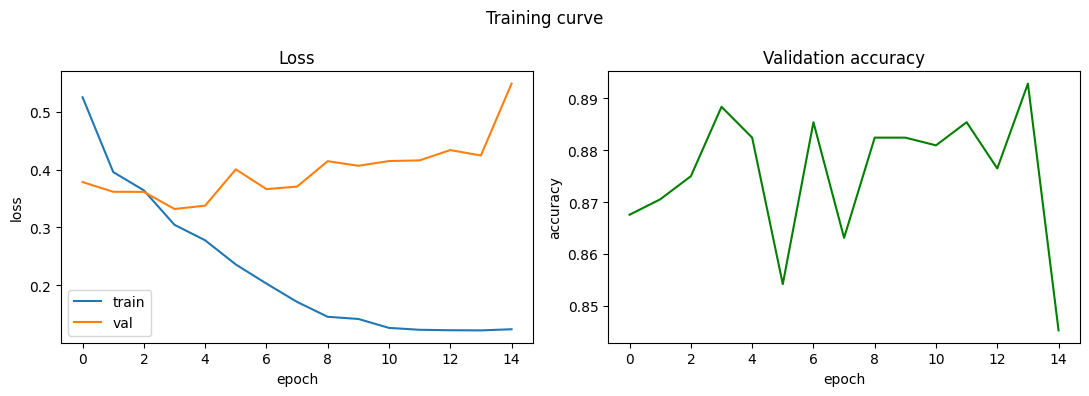

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
axes[0].set_title("Loss")
axes[1].plot(history["val_acc"], color="green")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Validation accuracy")
plt.suptitle("Training curve")
plt.tight_layout(); plt.show()

In [ ]:
@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    all_labels, all_preds, all_probs = [], [], []
    for features, labels in loader:
        features = features.to(DEVICE)
        logits = model(features)
        probs = torch.softmax(logits, dim=1)[:, 1]  # P(MI)
        preds = logits.argmax(dim=1).cpu().numpy()
        all_labels.extend(labels.numpy())
        all_preds.extend(preds)
        all_probs.extend(probs.cpu().numpy())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)

In [ ]:
y_true, y_pred, y_prob = get_predictions(model, test_loader)

acc = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn) if (tp + fn) else float("nan")   # recall on MI
specificity = tn / (tn + fp) if (tn + fp) else float("nan")   # recall on Normal
auc = roc_auc_score(y_true, y_prob) if len(set(y_true)) > 1 else float("nan")

print(f"Accuracy:    {acc:.3f}")
print(f"Sensitivity (MI recall):     {sensitivity:.3f}")
print(f"Specificity (Normal recall): {specificity:.3f}")
print(f"ROC-AUC:     {auc:.3f}")
print()
print(classification_report(y_true, y_pred, target_names=CLASSES))

Accuracy:    0.865
Sensitivity (MI recall):     0.836
Specificity (Normal recall): 0.894
ROC-AUC:     0.948

              precision    recall  f1-score   support

      Normal       0.84      0.89      0.87       330
  Myocardial       0.89      0.84      0.86       336

    accuracy                           0.86       666
   macro avg       0.87      0.87      0.86       666
weighted avg       0.87      0.86      0.86       666



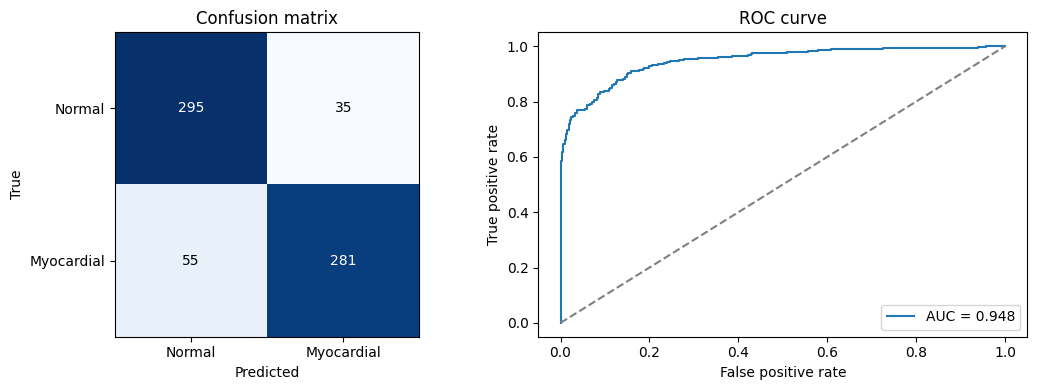

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(CLASSES)
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(CLASSES)
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
axes[0].set_title("Confusion matrix")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")

if len(set(y_true)) > 1:
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    axes[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    axes[1].plot([0, 1], [0, 1], "--", color="gray")
    axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
    axes[1].set_title("ROC curve"); axes[1].legend()

plt.tight_layout(); plt.show()

In [ ]:
test_results = test_df.reset_index(drop=True).copy()
test_results["y_true"] = y_true
test_results["p_mi"] = y_prob

patient_results = (
    test_results.groupby("patient_id")
    .agg(class_name=("class_name", "first"), y_true=("y_true", "first"),
         mean_p_mi=("p_mi", "mean"), n_sites=("site", "nunique"))
    .reset_index()
)
patient_results["y_pred"] = (patient_results["mean_p_mi"] >= 0.5).astype(int)

if len(patient_results) > 0:
    patient_acc = accuracy_score(patient_results["y_true"], patient_results["y_pred"])
    print(f"Per-patient accuracy (mean prob. across sites): {patient_acc:.3f}")
patient_results

Per-patient accuracy (mean prob. across sites): 0.964


,patient_id,class_name,y_true,mean_p_mi,n_sites,y_pred
0,Myocardial_Amat,Myocardial,1,0.870119,4,1
1,Myocardial_Ayi_Giswaty_Adiredja,Myocardial,1,0.777811,4,1
2,Myocardial_Elah_Hayati,Myocardial,1,0.513071,4,1
3,Myocardial_Eman_Sudirman,Myocardial,1,0.387119,4,0
4,Myocardial_Ibrahim_Sujana,Myocardial,1,0.973958,4,1
5,Myocardial_Iwan_Setiawan,Myocardial,1,0.909894,4,1
6,Myocardial_Karsih.,Myocardial,1,0.987789,4,1
7,Myocardial_Kosasih,Myocardial,1,0.961398,4,1
8,Myocardial_Nurhayati,Myocardial,1,0.672304,4,1
9,Myocardial_Rohmat,Myocardial,1,0.539781,4,1


In [ ]:
@torch.no_grad()
def predict_file(filepath, model=model):
    signal = pad_or_trim(load_and_resample(filepath))
    features = calculate_features(signal)
    features = torch.from_numpy(features).float().unsqueeze(0).to(DEVICE)  # [1, freq, time]
    logits = model(features)
    probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
    pred_idx = int(probs.argmax())
    return {"prediction": CLASSES[pred_idx], "P(Normal)": float(probs[0]), "P(MI)": float(probs[1])}

def predict_patient(site_filepaths, model=model):
    # Average P(MI) across a patient's site recordings (e.g. apex/llsb/lusb/rusb).
    probs_mi = [predict_file(f, model)["P(MI)"] for f in site_filepaths]
    mean_p_mi = float(np.mean(probs_mi))
    return {"prediction": "MI" if mean_p_mi >= 0.5 else "Normal",
            "P(MI)_per_site": probs_mi, "mean_P(MI)": mean_p_mi}

# Example:
# predict_file("/mnt/user-data/uploads/patient_1_Aan_apex.wav")
# predict_patient([
#     "/mnt/user-data/uploads/patient_1_Aan_apex.wav",
#     "/mnt/user-data/uploads/patient_1_Aan_llsb.wav",
#     "/mnt/user-data/uploads/patient_1_Aan_lusb.wav",
#     "/mnt/user-data/uploads/patient_1_Aan_rusb.wav",
# ])


--- Visualizing 5 examples from Myocardial Class ---


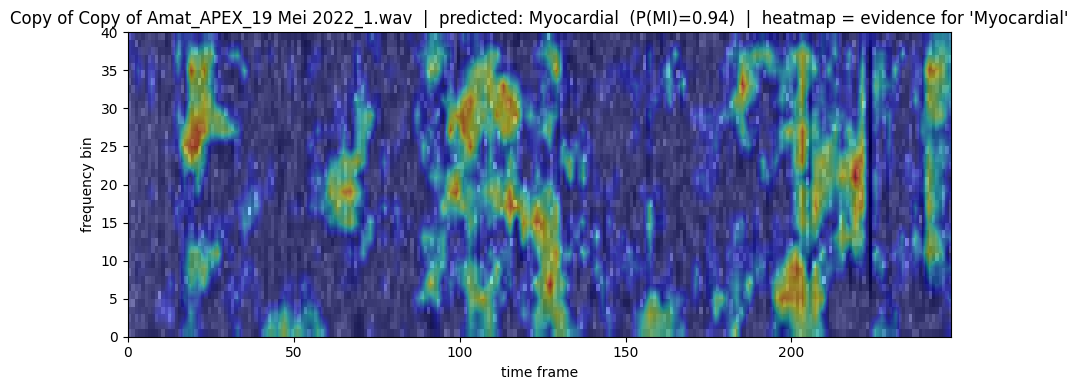

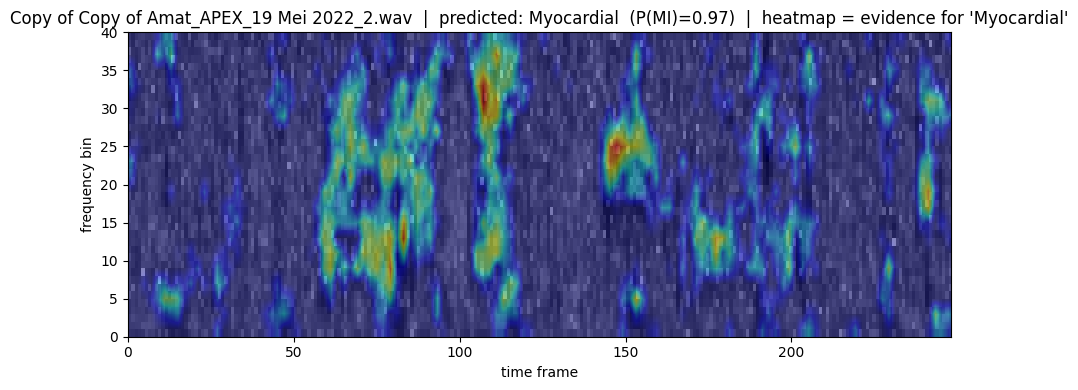

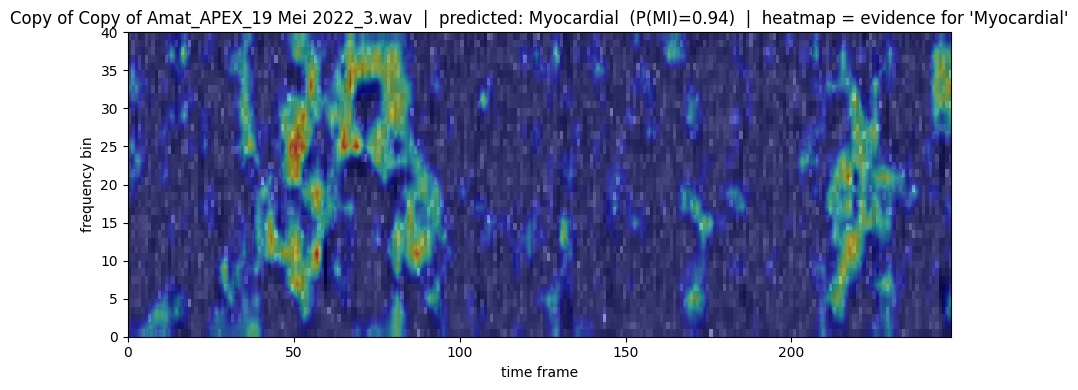

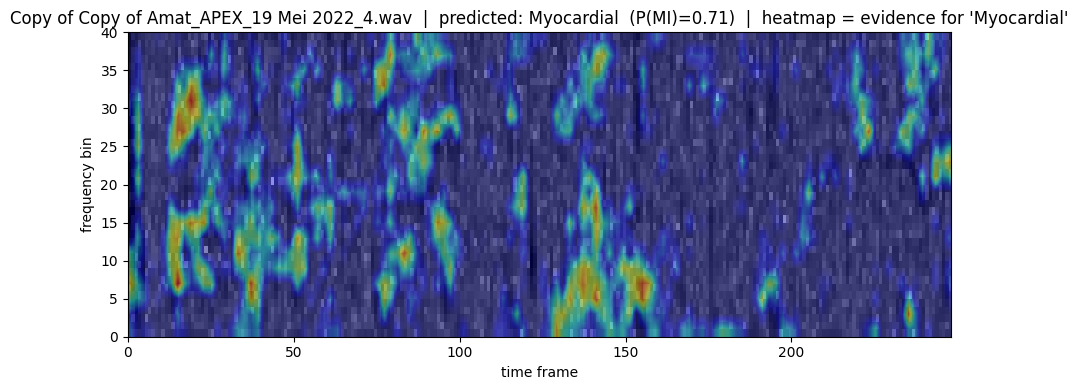

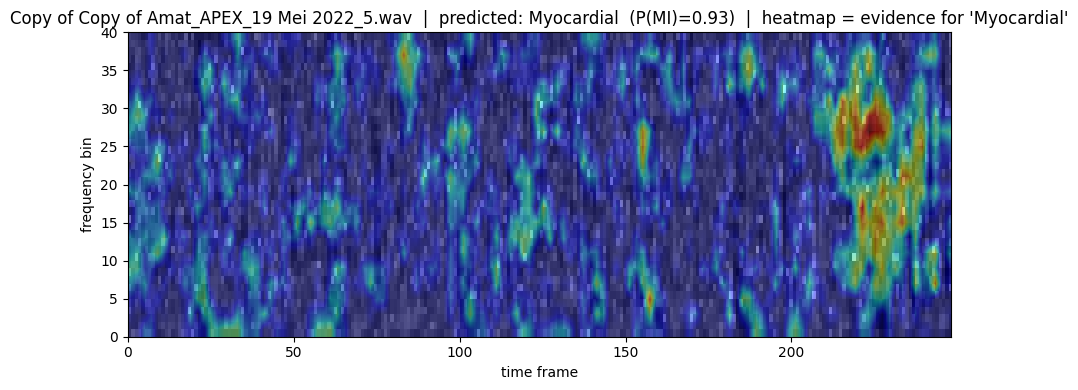


--- Visualizing 5 examples from Normal Class ---


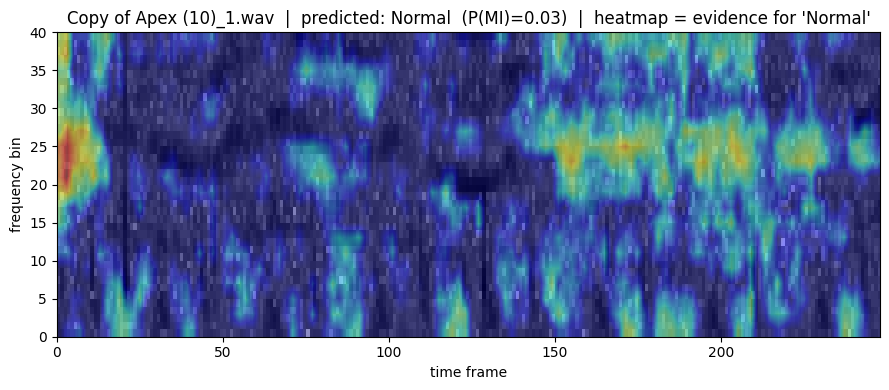

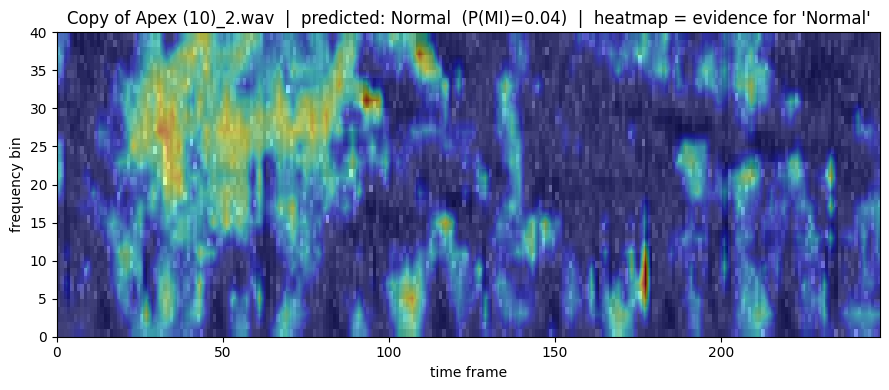

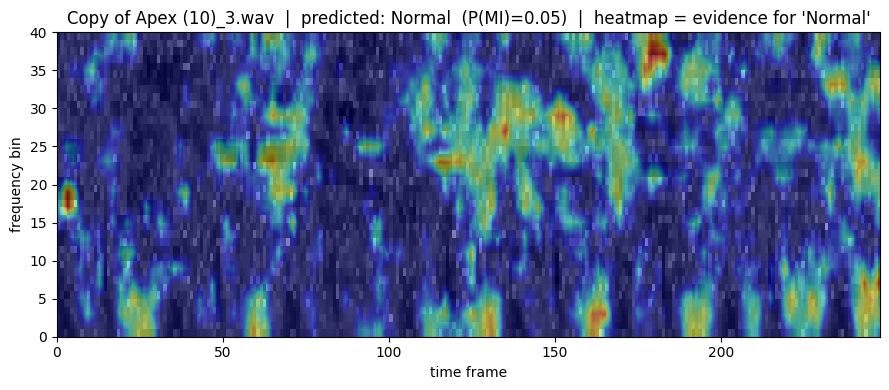

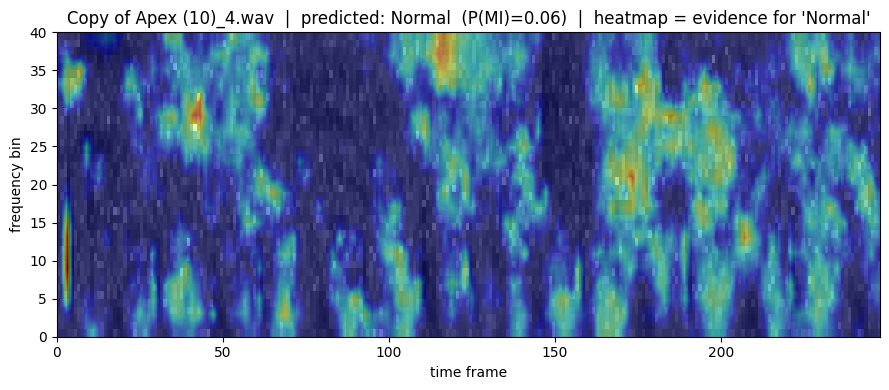

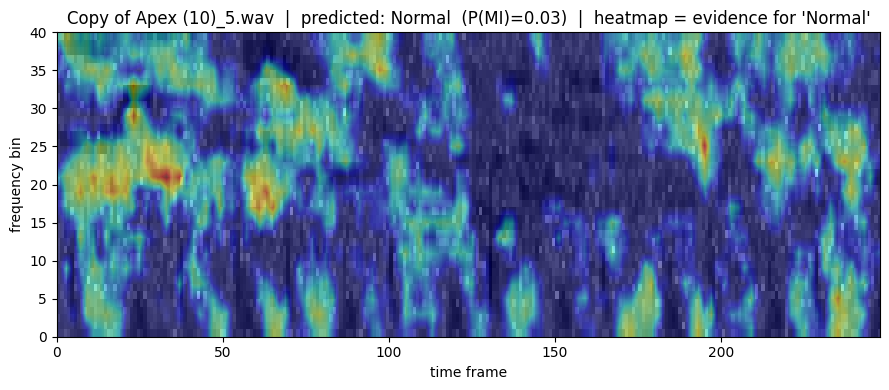

In [ ]:
class GradCAM:
    # Minimal Grad-CAM: hooks a conv layer's activations + gradients, and turns the
    # gradient-weighted activation map into a heatmap for one input.
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def __call__(self, x, class_idx=None):
        self.model.zero_grad()
        # cuDNN's fused GRU kernel only keeps what's needed for backward() when the forward
        # pass runs in train() mode. We want the model in eval() for deterministic
        # BatchNorm/Dropout, so instead we drop down to PyTorch's non-cuDNN RNN path just for
        # this forward+backward — avoids "cudnn RNN backward can only be called in training
        # mode" on GPU, and is a no-op on CPU (which never used cuDNN to begin with).
        with torch.backends.cudnn.flags(enabled=False):
            logits = self.model(x)
            probs = torch.softmax(logits, dim=1)[0].detach().cpu().numpy()
            if class_idx is None:
                class_idx = int(probs.argmax())
            logits[:, class_idx].backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)      # [1, C, 1, 1]
        cam = torch.relu((weights * self.activations).sum(dim=1))    # [1, F', T']
        cam = cam[0].cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)     # normalise to [0, 1]
        return cam, class_idx, probs


grad_cam = GradCAM(model, target_layer=model.conv2)

def plot_grad_cam(filepath, model=model, cam_engine=grad_cam, class_idx=None):
    signal = pad_or_trim(load_and_resample(filepath))
    feat = calculate_features(signal)  # [freq_bins, time_frames]
    x = torch.from_numpy(feat).float().unsqueeze(0).to(DEVICE)
    x.requires_grad_(True)

    was_training = model.training
    model.eval()
    cam, pred_idx, probs = cam_engine(x, class_idx=class_idx)
    model.train(was_training)

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.imshow(feat, aspect="auto", origin="lower", cmap="gray_r",
              extent=[0, feat.shape[1], 0, feat.shape[0]])
    ax.imshow(cam, aspect="auto", origin="lower", cmap="jet", alpha=0.45,
              extent=[0, feat.shape[1], 0, feat.shape[0]], interpolation="bilinear")
    ax.set_title(f"{pathlib.Path(filepath).name}  |  predicted: {CLASSES[pred_idx]}  "
                 f"(P(MI)={probs[1]:.2f})  |  heatmap = evidence for '{CLASSES[pred_idx]}'")
    ax.set_xlabel("time frame"); ax.set_ylabel("frequency bin")
    plt.tight_layout(); plt.show()
    return cam, pred_idx, probs

# Demo on 5 MI and 5 Normal recordings
demo_source = test_df if len(test_df) >= 10 else metadata
for cls in ["Myocardial", "Normal"]:
    rows = demo_source[demo_source["class_name"] == cls].head(5)
    if len(rows) > 0:
        print(f"\n--- Visualizing 5 examples from {cls} Class ---")
        for _, row in rows.iterrows():
            plot_grad_cam(row["filepath"])
    else:
        print(f"No {cls} recordings available to demo.")

No MI recordings available to demo.


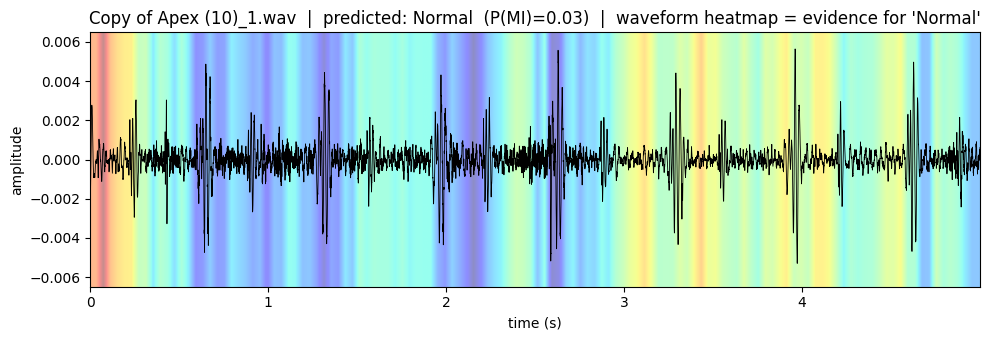

In [ ]:
def collapse_cam_to_waveform_importance(cam, n_stft_frames, signal_len, collapse="max",
                                          sample_rate=SAMPLE_RATE, hop_length=None, win_length=None):
    # Turn a [freq_bins, time_frames] Grad-CAM into a per-sample importance curve.
    hop_length = hop_length or int(WINDOW_STEP_S * sample_rate)
    win_length = win_length or int(WINDOW_LENGTH_S * sample_rate)

    time_curve = cam.max(axis=0) if collapse == "max" else cam.mean(axis=0)
    time_curve = (time_curve - time_curve.min()) / (time_curve.max() - time_curve.min() + 1e-8)

    # Center time (seconds) of each CAM time-bin, expressed on the STFT frame grid
    n_cam_bins = len(time_curve)
    bin_frame_idx = (np.arange(n_cam_bins) + 0.5) * (n_stft_frames / n_cam_bins) - 0.5
    bin_times = (bin_frame_idx * hop_length + win_length / 2) / sample_rate

    sample_times = np.arange(signal_len) / sample_rate
    waveform_importance = np.interp(sample_times, bin_times, time_curve)
    return waveform_importance, sample_times


def plot_waveform_cam(filepath, model=model, cam_engine=grad_cam, class_idx=None, collapse="max"):
    signal = pad_or_trim(load_and_resample(filepath))
    feat = calculate_features(signal)
    x = torch.from_numpy(feat).float().unsqueeze(0).to(DEVICE)

    model.eval()
    cam, pred_idx, probs = cam_engine(x, class_idx=class_idx)

    waveform_importance, sample_times = collapse_cam_to_waveform_importance(
        cam, n_stft_frames=feat.shape[1], signal_len=len(signal), collapse=collapse
    )

    fig, ax = plt.subplots(figsize=(10, 3.5))
    y_margin = max(np.abs(signal).max() * 1.15, 1e-6)
    ax.imshow(waveform_importance[np.newaxis, :], aspect="auto", cmap="jet", alpha=0.45,
              extent=[sample_times[0], sample_times[-1], -y_margin, y_margin], origin="lower")
    ax.plot(sample_times, signal, color="black", linewidth=0.6)
    ax.set_xlim(sample_times[0], sample_times[-1])
    ax.set_ylim(-y_margin, y_margin)
    ax.set_title(f"{pathlib.Path(filepath).name}  |  predicted: {CLASSES[pred_idx]}  "
                 f"(P(MI)={probs[1]:.2f})  |  waveform heatmap = evidence for '{CLASSES[pred_idx]}'")
    ax.set_xlabel("time (s)"); ax.set_ylabel("amplitude")
    plt.tight_layout(); plt.show()
    return waveform_importance, pred_idx, probs

for cls in ["MI", "Normal"]:
    rows = demo_source[demo_source["class_name"] == cls]
    if len(rows) > 0:
        plot_waveform_cam(rows.iloc[0]["filepath"])
    else:
        print(f"No {cls} recordings available to demo.")


--- Waveform Visualizations: 5 Examples from Myocardial Class ---


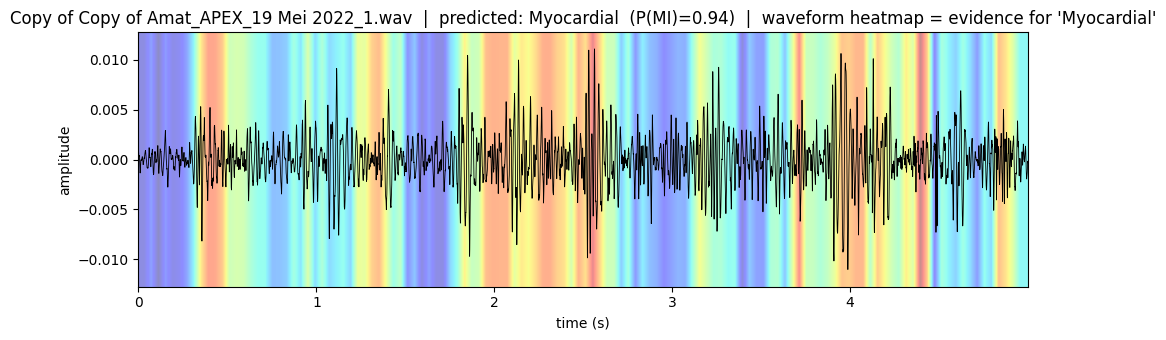

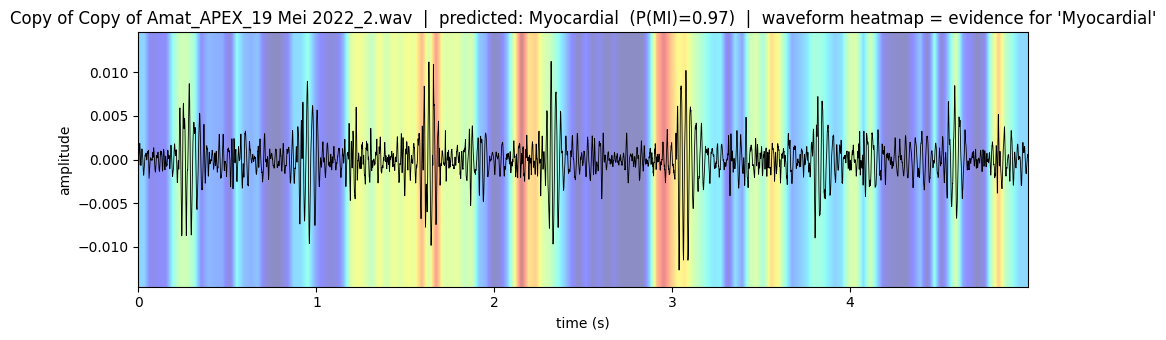

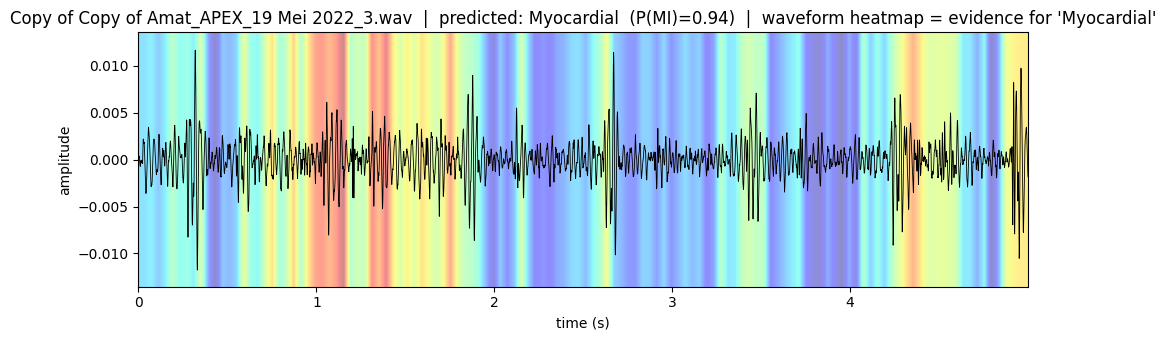

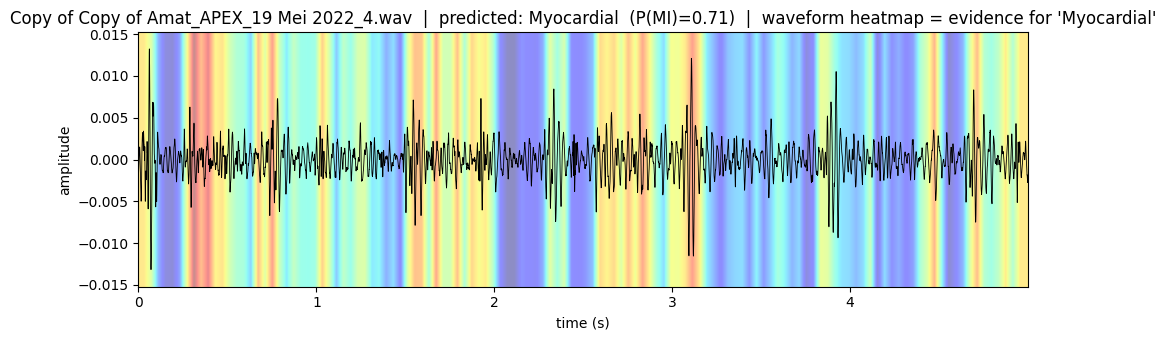

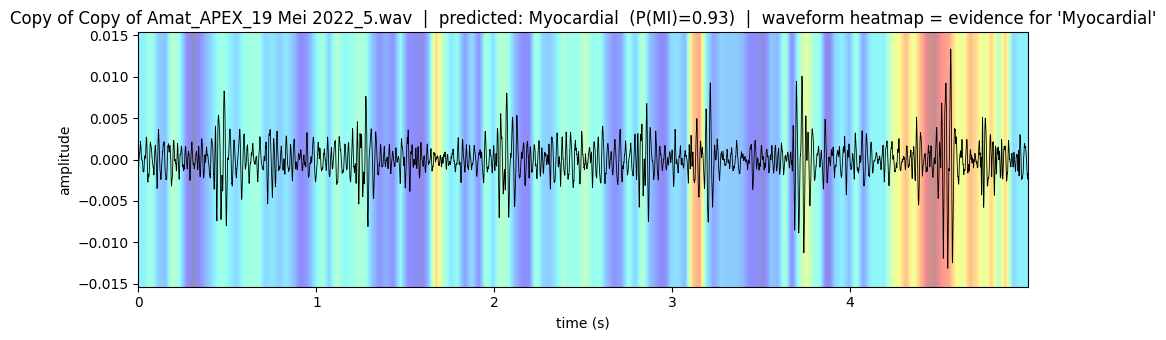


--- Waveform Visualizations: 5 Examples from Normal Class ---


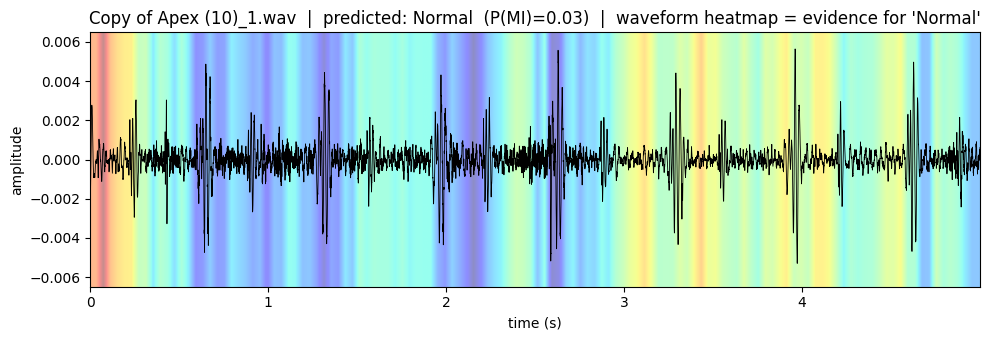

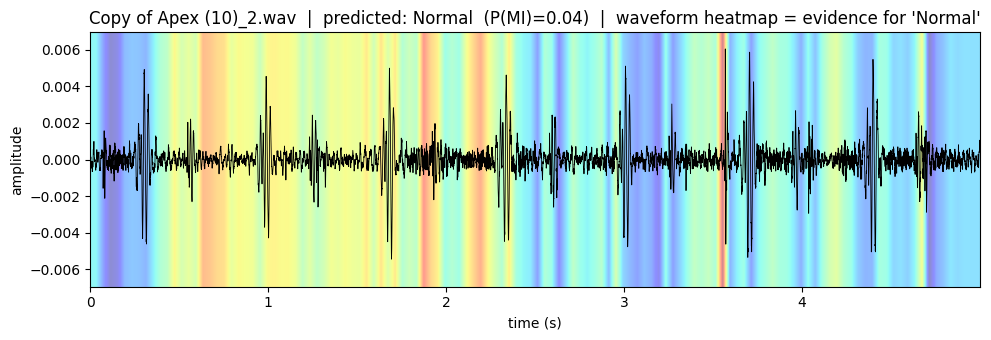

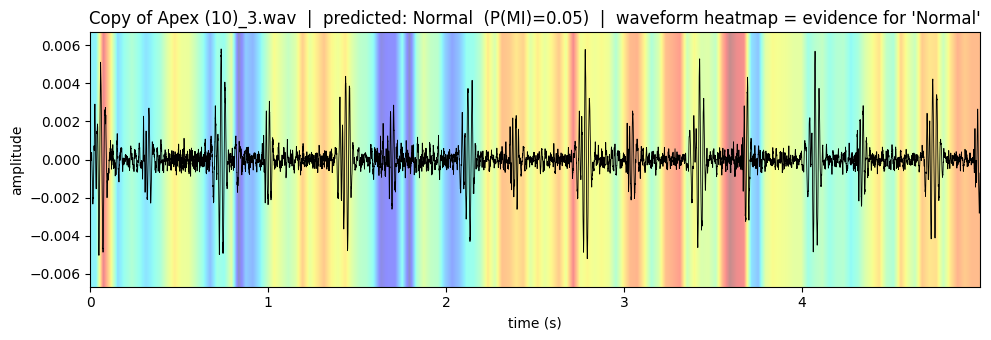

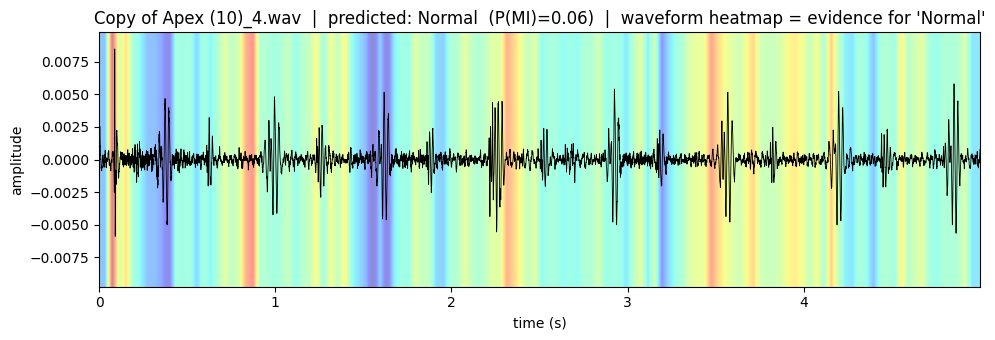

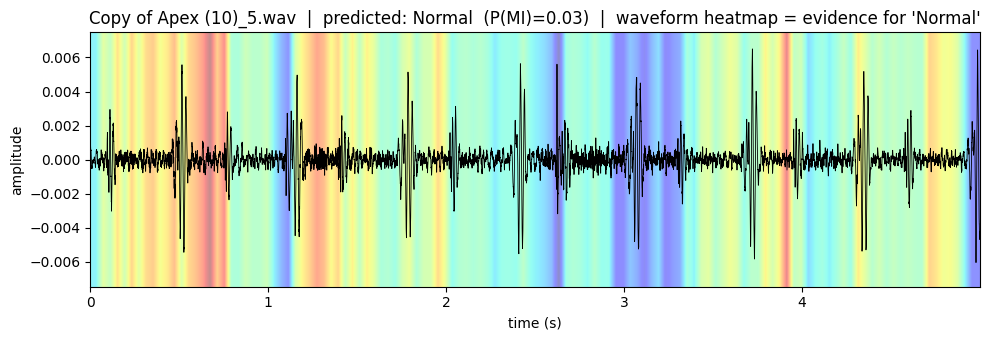

In [ ]:
# Visualizing 5 examples from each class using Waveform Grad-CAM
demo_source = test_df if len(test_df) >= 10 else metadata

for cls in ["Myocardial", "Normal"]:
    rows = demo_source[demo_source["class_name"] == cls].head(5)
    if len(rows) > 0:
        print(f"\n--- Waveform Visualizations: 5 Examples from {cls} Class ---")
        for _, row in rows.iterrows():
            plot_waveform_cam(row["filepath"])
    else:
        print(f"No {cls} recordings available to demo.")

In [ ]:
from sklearn.model_selection import StratifiedKFold

RUN_KFOLD_CV = True   # set True to run (takes ~N_FOLDS times as long as a single training run)
N_FOLDS = 5

def run_kfold_cv(metadata, model_fn, n_folds=N_FOLDS, verbose_folds=True, **train_kwargs):
    patient_df = metadata.groupby("patient_id").agg(label=("label", "first")).reset_index()
    class_counts = patient_df["label"].value_counts()
    if len(class_counts) < 2 or class_counts.min() < n_folds:
        print(f"Not enough patients per class {dict(class_counts)} for {n_folds}-fold CV "
              f"(need >= {n_folds} per class). Add more patients or lower N_FOLDS.")
        return None

    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    fold_rows = []
    for fold_idx, (tr_idx, va_idx) in enumerate(skf.split(patient_df, patient_df["label"])):
        train_patients = patient_df.iloc[tr_idx]["patient_id"]
        val_patients = patient_df.iloc[va_idx]["patient_id"]
        fold_train_df = metadata[metadata["patient_id"].isin(train_patients)]
        fold_val_df = metadata[metadata["patient_id"].isin(val_patients)]

        fold_train_loader = DataLoader(PCGDataset(fold_train_df), batch_size=BATCH_SIZE, shuffle=True)
        fold_val_loader = DataLoader(PCGDataset(fold_val_df), batch_size=BATCH_SIZE, shuffle=False)
        fold_class_weights = compute_class_weights(fold_train_df).to(DEVICE)

        if verbose_folds:
            print(f"\n=== Fold {fold_idx + 1}/{n_folds} "
                  f"(train patients {len(train_patients)}, val patients {len(val_patients)}) ===")
        fold_model, _, fold_val_loss = train_model(
            fold_train_loader, fold_val_loader, model_fn=model_fn,
            class_weights=fold_class_weights, verbose=False, **train_kwargs
        )
        y_t, y_p, y_pr = get_predictions(fold_model, fold_val_loader)
        acc = accuracy_score(y_t, y_p)
        auc = roc_auc_score(y_t, y_pr) if len(set(y_t)) > 1 else float("nan")
        cm = confusion_matrix(y_t, y_p, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        sens = tp / (tp + fn) if (tp + fn) else float("nan")
        spec = tn / (tn + fp) if (tn + fp) else float("nan")
        if verbose_folds:
            print(f"Fold {fold_idx + 1}: val_loss={fold_val_loss:.4f}  val_acc={acc:.3f}  "
                  f"val_auc={auc:.3f}  sensitivity={sens:.3f}  specificity={spec:.3f}")
        fold_rows.append({"fold": fold_idx + 1, "val_loss": fold_val_loss, "val_acc": acc,
                          "val_auc": auc, "sensitivity": sens, "specificity": spec})

    results_df = pd.DataFrame(fold_rows)
    print("\n=== K-fold summary ===")
    print(results_df)
    for col in ["val_loss", "val_acc", "val_auc", "sensitivity", "specificity"]:
        print(f"{col}: {results_df[col].mean():.4f} ± {results_df[col].std():.4f}")
    return results_df

if RUN_KFOLD_CV:
    kfold_results = run_kfold_cv(metadata, model_fn=lambda: make_model(n_freq_bins), n_folds=N_FOLDS)
else:
    print("Skipped (RUN_KFOLD_CV=False). Set to True once you have enough patients per class.")


=== Fold 1/5 (train patients 112, val patients 28) ===
Fold 1: val_loss=0.2620  val_acc=0.930  val_auc=0.975  sensitivity=0.902  specificity=0.958

=== Fold 2/5 (train patients 112, val patients 28) ===
Fold 2: val_loss=0.3498  val_acc=0.884  val_auc=0.938  sensitivity=0.851  specificity=0.917

=== Fold 3/5 (train patients 112, val patients 28) ===
Fold 3: val_loss=0.3809  val_acc=0.863  val_auc=0.937  sensitivity=0.780  specificity=0.946

=== Fold 4/5 (train patients 112, val patients 28) ===
Fold 4: val_loss=0.3923  val_acc=0.857  val_auc=0.928  sensitivity=0.860  specificity=0.855

=== Fold 5/5 (train patients 112, val patients 28) ===
Fold 5: val_loss=0.2960  val_acc=0.909  val_auc=0.972  sensitivity=0.932  specificity=0.886

=== K-fold summary ===
   fold  val_loss   val_acc   val_auc  sensitivity  specificity
0     1  0.262024  0.930060  0.975393     0.901786     0.958333
1     2  0.349764  0.883929  0.938412     0.851190     0.916667
2     3  0.380917  0.863095  0.936977     0.

Running 5 folds to collect predictions for confusion matrix...
Fold 1 complete.
Fold 2 complete.
Fold 3 complete.
Fold 4 complete.
Fold 5 complete.


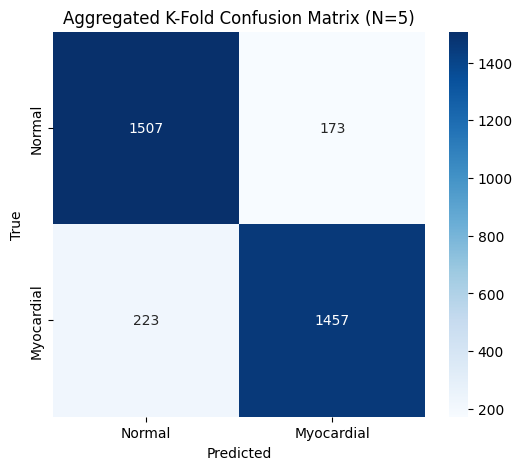

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_kfold_confusion_matrix(metadata, n_folds=5):
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    patient_df = metadata.groupby("patient_id").agg(label=("label", "first")).reset_index()

    all_y_true = []
    all_y_pred = []

    print(f"Running {n_folds} folds to collect predictions for confusion matrix...")

    for fold_idx, (tr_idx, va_idx) in enumerate(skf.split(patient_df, patient_df['label'])):
        val_patients = patient_df.iloc[va_idx]["patient_id"]
        fold_train_df = metadata[~metadata["patient_id"].isin(val_patients)]
        fold_val_df = metadata[metadata["patient_id"].isin(val_patients)]

        fold_train_loader = DataLoader(PCGDataset(fold_train_df), batch_size=BATCH_SIZE, shuffle=True)
        fold_val_loader = DataLoader(PCGDataset(fold_val_df), batch_size=BATCH_SIZE, shuffle=False)

        fold_model, _, _ = train_model(
            fold_train_loader, fold_val_loader,
            model_fn=lambda: make_model(n_freq_bins),
            class_weights=compute_class_weights(fold_train_df).to(DEVICE),
            verbose=False, epochs=20  # Reduced epochs for faster visualization
        )

        y_t, y_p, _ = get_predictions(fold_model, fold_val_loader)
        all_y_true.extend(y_t)
        all_y_pred.extend(y_p)
        print(f"Fold {fold_idx+1} complete.")

    # Calculate confusion matrix
    cm_total = confusion_matrix(all_y_true, all_y_pred)

    # Plot
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_total, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'Aggregated K-Fold Confusion Matrix (N={n_folds})')
    plt.show()

# Execute visualization
plot_kfold_confusion_matrix(metadata, n_folds=N_FOLDS)

In [ ]:
RUN_HYPERPARAM_SEARCH = True   # set True to run (retrains a full model per row below)

param_grid = [
    {"lr": 1e-3, "dropout": 0.3, "weight_decay": 1e-4, "rnn_hidden": 64},  # current default
    {"lr": 3e-4, "dropout": 0.3, "weight_decay": 1e-4, "rnn_hidden": 64},  # lower LR
    {"lr": 1e-3, "dropout": 0.5, "weight_decay": 1e-3, "rnn_hidden": 64},  # heavier regularisation
    {"lr": 1e-3, "dropout": 0.3, "weight_decay": 1e-4, "rnn_hidden": 32},  # smaller model
]

if RUN_HYPERPARAM_SEARCH:
    search_rows = []
    for cfg in param_grid:
        print(f"\n=== Trying {cfg} ===")
        cfg_model_fn = lambda cfg=cfg: make_model(n_freq_bins, rnn_hidden=cfg["rnn_hidden"],
                                                   dropout=cfg["dropout"])
        _, _, val_loss = train_model(
            train_loader, val_loader, model_fn=cfg_model_fn, class_weights=class_weights,
            lr=cfg["lr"], weight_decay=cfg["weight_decay"], epochs=EPOCHS, patience=10, verbose=False,
        )
        print(f"  -> best val_loss = {val_loss:.4f}")
        search_rows.append({**cfg, "val_loss": val_loss})

    search_df = pd.DataFrame(search_rows).sort_values("val_loss").reset_index(drop=True)
    print("\n=== Hyperparameter search results (best first) ===")
    print(search_df)
else:
    print("Skipped (RUN_HYPERPARAM_SEARCH=False). Set to True to try the grid above, or edit "
          "param_grid with your own values.")


=== Trying {'lr': 0.001, 'dropout': 0.3, 'weight_decay': 0.0001, 'rnn_hidden': 64} ===


NameError: name 'class_weights' is not defined

In [ ]:
def measure_inference_time(model_fn, sample_input, n_repeats=20):
    m = model_fn()
    m.eval()
    x = sample_input.to(DEVICE)
    with torch.no_grad():
        for _ in range(3):          # warm-up, not timed
            m(x)
        start = time.time()
        for _ in range(n_repeats):
            m(x)
        elapsed = time.time() - start
    del m
    return (elapsed / n_repeats) * 1000   # ms per forward pass


def run_ablation_study(metadata, model_specs, n_folds=N_FOLDS, fit_final_models=True, **train_kwargs):
    summary_rows = []
    per_fold_results = {}
    final_models = {}

    sample_x = next(iter(train_loader))[0][:1]   # one example, [1, freq, time], for timing

    for name, model_fn in model_specs.items():
        print(f"\n{'=' * 60}\n{name}\n{'=' * 60}")
        probe = model_fn()
        n_params = sum(p.numel() for p in probe.parameters() if p.requires_grad)
        del probe
        inf_time_ms = measure_inference_time(model_fn, sample_x)
        print(f"{n_params:,} parameters | {inf_time_ms:.2f} ms/forward-pass (batch size 1)")

        fold_df = run_kfold_cv(metadata, model_fn=model_fn, n_folds=n_folds,
                               verbose_folds=False, **train_kwargs)
        per_fold_results[name] = fold_df

        if fold_df is not None:
            row = {"model": name, "n_params": n_params, "inference_ms": inf_time_ms}
            for col in ["val_loss", "val_acc", "val_auc", "sensitivity", "specificity"]:
                row[f"{col}_mean"] = fold_df[col].mean()
                row[f"{col}_std"] = fold_df[col].std()
            summary_rows.append(row)

        if fit_final_models:
            print(f"Fitting one final {name} on the main train/val split "
                  f"(for the qualitative explanation comparison below)...")
            final_model, _, _ = train_model(
                train_loader, val_loader, model_fn=model_fn,
                class_weights=class_weights, verbose=False, **train_kwargs
            )
            final_models[name] = final_model

    summary_df = pd.DataFrame(summary_rows) if summary_rows else None
    return summary_df, per_fold_results, final_models


RUN_ABLATION_STUDY = True   # set True once you have enough patients per class

if RUN_ABLATION_STUDY:
    model_specs = {
        "RNN (baseline)": lambda: RNNBaseline(n_freq_bins).to(DEVICE),
        "CRNN": lambda: make_model(n_freq_bins),
        "CRNN + Attention": lambda: CRNNAttention(n_freq_bins).to(DEVICE),
    }
    ablation_summary, ablation_folds, ablation_models = run_ablation_study(
        metadata, model_specs, n_folds=N_FOLDS
    )
    if ablation_summary is not None:
        print("\n=== Ablation summary ===")
        print(ablation_summary)
else:
    print("Skipped (RUN_ABLATION_STUDY=False). Set to True once you have enough patients per class.")
    ablation_summary, ablation_folds, ablation_models = None, {}, {}